# Deliverable 1

## Reuseable function for fetching data

This function would let us retreive different type of data, based on what the Task is asking for. Reusiong this function will save us time and space when answering this deliverable.

The code for retrieving and structuring the data is adapted from MET's Python example for Frost [1].

In [17]:
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

client_id = Path("frost_client_id.txt").read_text().strip()

In [18]:
def get_frost_data(element, referencetime, source='SN17850') -> pd.DataFrame:
    """Fetch daily observations from Frost and return them as a DataFrame."""
    # Define endpoint and parameters
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': source,
        'elements': element,
        'referencetime': referencetime,
    }
    # Issue an HTTP GET request and extract JSON data
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    response_json = r.json()

    # Stop with a clear message if the request did not work
    if r.status_code != 200:
        raise RuntimeError('Error %s: %s (%s)' % (
            r.status_code,
            response_json['error']['message'],
            response_json['error']['reason'],
        ))
    data = response_json['data']

    # Build a DataFrame with one row per observation
    rows = []
    for i in range(len(data)):
        row = pd.DataFrame(data[i]['observations'])
        row['referenceTime'] = data[i]['referenceTime']
        rows.append(row)
    df = pd.concat(rows, ignore_index=True)

    # Convert time and keep one measurement per day
    df['referenceTime'] = pd.to_datetime(df['referenceTime'], utc=True).dt.tz_convert(None)
    df = df[df['timeOffset'] == df['timeOffset'].iloc[0]]
    return df[['referenceTime', 'value']].reset_index(drop=True)

# Task 1

The data comes back as a list with one entry pr day. Each entry contains a list of observations. The next cells will turn this into a pd.Dataframe. The MET version is using an older code, so pd.concat() will be used insteand of df.append()

In [19]:
df = get_frost_data('mean(air_temperature P1D)', '2025-01-01/2026-01-01')

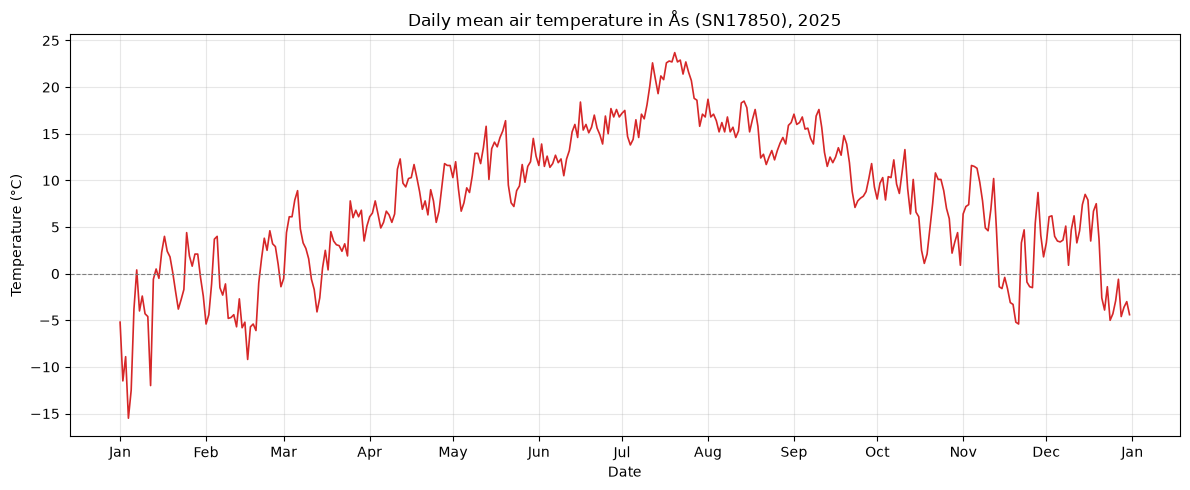

In [20]:
# Plot the daily mean temperature
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['referenceTime'], df['value'], color='tab:red', linewidth=1.2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås (SN17850), 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [21]:
# Summary table with mean, median, min and max temperature
summary = pd.DataFrame({
    'Temperature 2025 (°C)': [
        df['value'].mean(),
        df['value'].median(),
        df['value'].min(),
        df['value'].max(),
    ]
}, index=['Mean', 'Median', 'Min', 'Max']).round(1)

print(summary)

        Temperature 2025 (°C)
Mean                      7.9
Median                    8.3
Min                     -15.5
Max                      23.7


### Discussion

The plot shows the normal seasonal cycle for Ås. It is cold in January and February, the temperature rises through spring, peaks in the second half of July and then falls again through autumn. The coldest day was in early January with -15.5 °C, and the warmest was in late July with 23.7 °C.

The mean temperature for 2025 was 7.9 °C and the median 8.3 °C. The median is a bit higher than the mean because a few very cold days in January pull the mean down. Most of the year is therefore slightly warmer than the mean suggests.

We also see that the temperature varies a lot more from day to day in winter than in summer. In January, February and December it jumps several degrees between days, and goes above and below 0 °C many times. In summer the curve is much smoother.

# Task 2

The next block retrieves the daily precipitation for 2025 from the same station.

In [22]:
precip = get_frost_data('sum(precipitation_amount P1D)', '2025-01-01/2026-01-01')

In [ ]:
# Rename 'value' so each column says what it holds
temp_daily = df.rename(columns={'value': 'temp'})[['referenceTime', 'temp']]
precip_daily = precip.rename(columns={'value': 'precip'})[['referenceTime', 'precip']]

# Strip the time of day so both tables use the same date key
temp_daily['date'] = temp_daily['referenceTime'].dt.normalize()
precip_daily['date'] = precip_daily['referenceTime'].dt.normalize()

# Keep only the days that exist in both tables (inner join)
weather = pd.merge(
    temp_daily[['date', 'temp']],
    precip_daily[['date', 'precip']],
    on='date',
    how='inner',
)

print(f'Days with both temperature and precipitation: {len(weather)}')

Days with both temperature and precipitation: 365


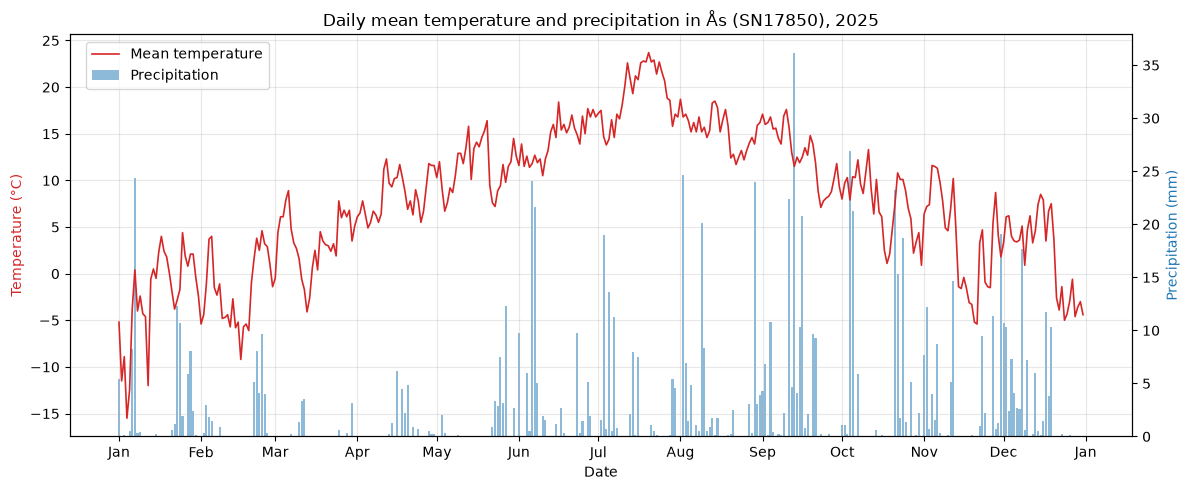

In [24]:
# Plot temperature (line, left axis) and precipitation (bars, right axis)
fig, ax1 = plt.subplots(figsize=(12, 5))

ax2 = ax1.twinx()
ax2.bar(weather['date'], weather['value_precip'], color='tab:blue', alpha=0.5, label='Precipitation')
ax2.set_ylabel('Precipitation (mm)', color='tab:blue')

ax1.plot(weather['date'], weather['value_temp'], color='tab:red', linewidth=1.2, label='Mean temperature')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.set_xlabel('Date')
ax1.set_zorder(ax2.get_zorder() + 1)   # draw the temperature line on top of the bars
ax1.patch.set_visible(False)

ax1.set_title('Daily mean temperature and precipitation in Ås (SN17850), 2025')
ax1.grid(alpha=0.3)
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.92))

ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

fig.tight_layout()
plt.show()

In [25]:
# Summary of precipitation in 2025
summary_precip = pd.DataFrame({
    'Precipitation 2025': [
        precip['value'].sum(),
        (precip['value'] >= 1).sum(),
        precip['value'].max(),
        precip.loc[precip['value'].idxmax(), 'referenceTime'].date(),
    ]
}, index=['Total (mm)', 'Days with ≥ 1 mm', 'Max per day (mm)', 'Wettest day'])

print(summary_precip)

                 Precipitation 2025
Total (mm)                    942.2
Days with ≥ 1 mm                123
Max per day (mm)               36.1
Wettest day              2025-09-13


### Discussion

We chose to show temperature as a line and precipitation as bars. Temperature changes gradually from day to day, so a line shows the trend best. Precipitation is an amount summed for each day, and many days have no rain at all, so bars show each day separately. A line would make it look like it rained continuously between the days. Since °C and mm have different units and scales, we used two y-axes so neither of them gets squeezed flat.

In 2025 there was 942.2 mm of precipitation in total, and 123 days had at least 1 mm. The wettest day was 13 September with 36.1 mm. The plot shows that March, April and May were quite dry with only small amounts, while most of the large events came from June and through autumn, especially in August, September and October. We do not see a clear relationship between temperature and precipitation day by day.

One thing to note is that precipitation is measured from 06 to 06 the next morning, while the temperature is a mean for the day. When we combine them on the date, the precipitation for a day therefore partly covers the next night. For a plot over a whole year this does not matter much, but it would matter if we compared single days.

# Task 3

In [26]:
df_1925 = get_frost_data('mean(air_temperature P1D)', '1925-01-01/1926-01-01')
print('Number of days in 1925: %s' % len(df_1925))

Number of days in 1925: 365


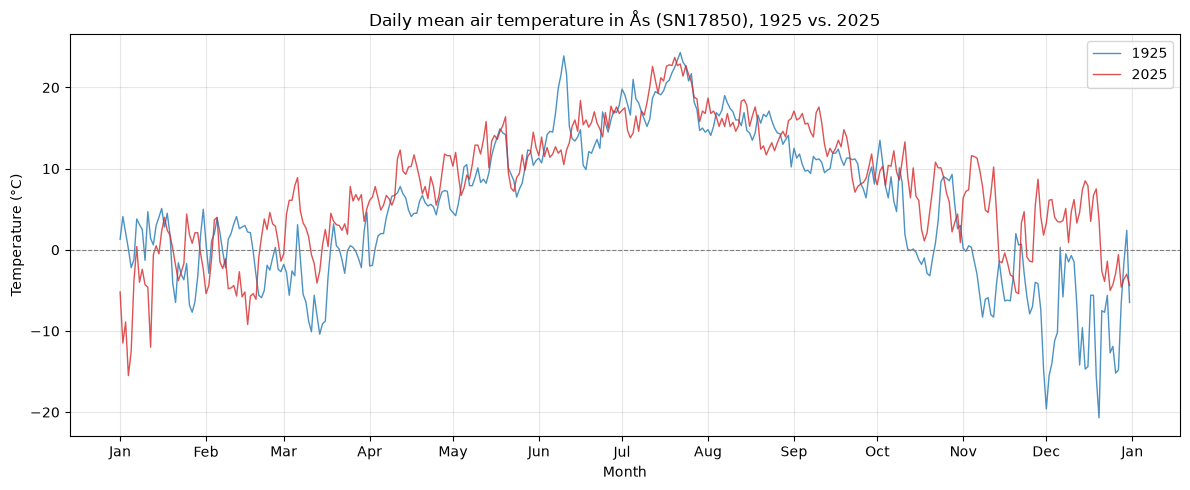

In [27]:
# Shift 1925 forward 100 years so both years share the same x-axis
df_1925['plotTime'] = df_1925['referenceTime'] + pd.DateOffset(years=100)

# Plot both years in the same figure
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_1925['plotTime'], df_1925['value'], color='tab:blue', linewidth=1, alpha=0.8, label='1925')
ax.plot(df['referenceTime'], df['value'], color='tab:red', linewidth=1, alpha=0.8, label='2025')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås (SN17850), 1925 vs. 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [28]:
# Summary table for both years
summary_compare = pd.DataFrame({
    '1925 (°C)': [df_1925['value'].mean(), df_1925['value'].median(),
                  df_1925['value'].min(), df_1925['value'].max()],
    '2025 (°C)': [df['value'].mean(), df['value'].median(),
                  df['value'].min(), df['value'].max()],
}, index=['Mean', 'Median', 'Min', 'Max'])
summary_compare['Difference (°C)'] = summary_compare['2025 (°C)'] - summary_compare['1925 (°C)']

print(summary_compare.round(1))

        1925 (°C)  2025 (°C)  Difference (°C)
Mean          5.3        7.9              2.6
Median        5.3        8.3              3.0
Min         -20.7      -15.5              5.2
Max          24.3       23.7             -0.6


### Discussion

To get both years in the same plot we moved the 1925 dates 100 years forward, so both years use the same x-axis. Neither 1925 nor 2025 are leap years, so the days line up exactly. We got data for all 365 days in 1925 as well.

2025 was clearly warmer than 1925. The mean was 7.9 °C against 5.3 °C, which is 2.6 °C warmer, and the median was 3.0 °C higher. The coldest day in 1925 was -20.7 °C, compared to -15.5 °C in 2025. The warmest day was actually a bit warmer in 1925, with 24.3 °C against 23.7 °C.

The plot shows that the difference is mostly in the cold part of the year. November and December 1925 were much colder, with long periods well below -5 °C and down to around -20 °C, while 2025 stayed mostly above 0 °C in the same period. March 1925 was also colder. In summer the two years are quite similar, and early January was actually colder in 2025.

This fits with the warming trend in Norway, where winters have warmed more than summers. But we have to be careful, since one year against one year says little on its own. The temperature varies a lot from year to year, so other years could give a different result. A better comparison would be to use averages over 30 years, for example 1901–1930 against 1991–2020. The instruments and surroundings of the station may also have changed over 100 years.

# Task 4

In [ ]:
import yaml


def get_station_info(station) -> tuple[str, str]:
    """Return (station_id, station_name) from Frost's sources endpoint.
    The station can be given as an ID (e.g. 'SN17850') or as a name (e.g. 'Ås')."""

    if station.upper().startswith('SN'):
        parameters = {'ids': station.upper()}
    else:
        parameters = {'name': station}
    r = requests.get('https://frost.met.no/sources/v0.jsonld', parameters, auth=(client_id, ''))
    
    if r.status_code != 200:
        raise ValueError('No station found for %s' % station)
    source = r.json()['data'][0]
    return source['id'], source.get('shortName', source['name'])



def count_heatwaves(station, year, threshold=27, min_days=5) -> int:
    """Count heatwaves (min_days or more consecutive days with max temperature >= threshold)
    for a station and year, and write a summary to a YAML file."""
    station_id, station_name = get_station_info(station)
    referencetime = '%s-01-01/%s-01-01' % (year, year + 1)
    df_max = get_frost_data('max(air_temperature P1D)', referencetime, source=station_id)

    # Use one row per calendar day, so that missing days break a period
    daily = df_max.set_index(df_max['referenceTime'].dt.normalize())['value']
    all_days = pd.date_range('%s-01-01' % year, '%s-12-31' % year, freq='D')
    daily = daily.reindex(all_days)

    # Mark hot days and give each run of consecutive equal values its own group number
    hot = daily >= threshold
    group = (hot != hot.shift()).cumsum()

    dates = []
    for _, days in daily[hot].groupby(group[hot]):
        if len(days) >= min_days:
            dates.append('%s - %s' % (days.index[0].strftime('%Y-%m-%d'),
                                      days.index[-1].strftime('%Y-%m-%d')))

    summary = {
        'dates': dates,
        'station_id': station_id,
        'station_name': station_name,
        'year': year,
    }

    filename = 'heatwave_summary_%s_%s.yml' % (station_id, year)
    with open(filename, 'w') as f:
        yaml.dump(summary, f)
    print('Summary written to %s' % filename)

    return len(dates)

In [30]:
n = count_heatwaves('SN17850', 2025)
print('Number of heatwaves in Ås in 2025: %s' % n)
print(Path('heatwave_summary_SN17850_2025.yml').read_text())

Summary written to heatwave_summary_SN17850_2025.yml
Number of heatwaves in Ås in 2025: 1
dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



### Discussion

We used the Norwegian definition of a heatwave, which is five or more days in a row with a max temperature of at least 27 °C [3]. Our function found one heatwave in Ås in 2025, from 16 to 20 July. The max temperatures in this period were between 28.3 and 30.8 °C.

July had several other hot days that did not count. 11 and 12 July were only two days in a row. On 21 July the max temperature fell below 27 °C, which broke up what would otherwise have been a heatwave from 16 to 25 July, since 22, 24 and 25 July were also above 27 °C. This shows how strict the definition is, where one slightly cooler day decides if it is one long heatwave or not. No days in August reached 27 °C.

The example YAML file had two heatwaves, 23–30 July and 13–22 August. These dates do not match the data from Frost, so we only used the example file as a template for the format. Our output has exactly the same structure.

The function works for any station and year, and the station can be given as either an ID or a name. Missing days are treated as a break, so two hot periods with missing data between them are not counted as one heatwave. The threshold uses `>= 27`, so a day with exactly 27 °C counts, as in the definition.

# Task 5

The moving average smooths out the daily variation and makes the seasonal trend easier to see.

In [31]:
def moving_average(values, window=7) -> pd.Series:
    """Return the moving average of a numeric series over the given number of days."""
    return values.rolling(window=window, min_periods=1).mean()

In [32]:
# Apply the function to the 2025 mean temperature from Task 1
df['moving_avg'] = moving_average(df['value'], window=7)
print(df[['referenceTime', 'value', 'moving_avg']].head(10))

  referenceTime  value  moving_avg
0    2025-01-01   -5.2   -5.200000
1    2025-01-02  -11.5   -8.350000
2    2025-01-03   -8.9   -8.533333
3    2025-01-04  -15.5  -10.275000
4    2025-01-05  -12.5  -10.720000
5    2025-01-06   -3.8   -9.566667
6    2025-01-07    0.4   -8.142857
7    2025-01-08   -4.0   -7.971429
8    2025-01-09   -2.4   -6.671429
9    2025-01-10   -4.3   -6.014286


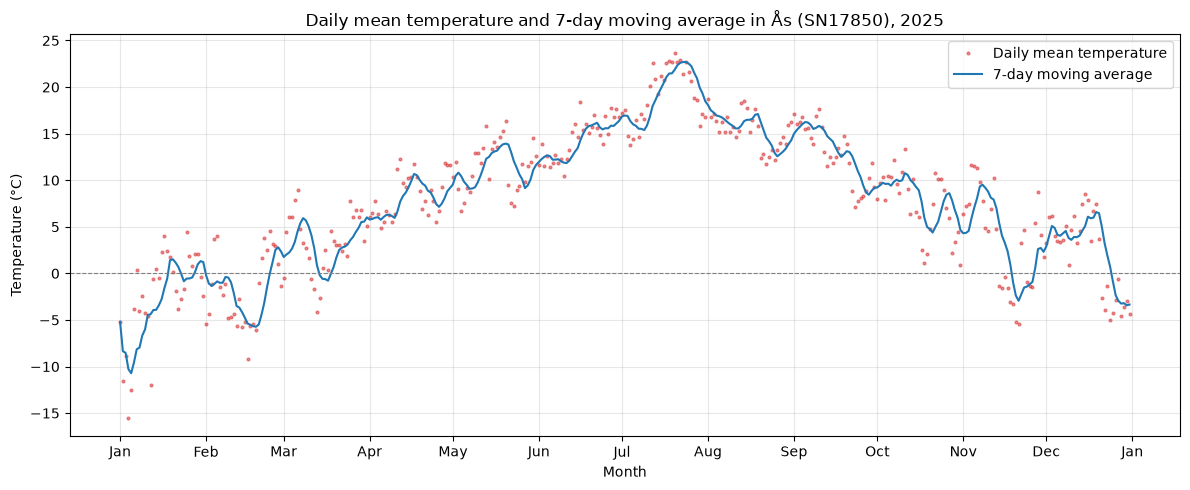

In [33]:
# Plot daily temperature as points and the moving average as a line
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['referenceTime'], df['value'], '.', color='tab:red',
        markersize=4, alpha=0.5, label='Daily mean temperature')
ax.plot(df['referenceTime'], df['moving_avg'], color='tab:blue',
        linewidth=1.5, label='7-day moving average')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean temperature and 7-day moving average in Ås (SN17850), 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()


### Discussion

The 7-day moving average removes most of the day-to-day variation and makes it easier to see the longer trends. In the daily points, single cold or warm days stand out, while the line shows the periods. We can for example see the cold start of January, a cold period in mid February, the steady rise through spring, the warm period in the second half of July, and a short cold period in late November before it gets milder again in early December.

The moving average looks backwards in time, so each value is the mean of the day and the six days before. Because of this the line comes a few days after the points when the temperature changes quickly, which is visible for example when it drops at the end of November and the end of December. A centered moving average would follow the points better, but would then use days after the date.

We used min_periods=1, so the first six days of the year are an average of fewer than seven days. This is why the start of the line follows the points more closely. The other option would be to leave these days empty, so the line starts on 7 January.

# References

[1] Norwegian Meteorological Institute. *Frost – Python example*. https://frost.met.no/python_example.html (accessed 13 October 2026)

[2] Norwegian Meteorological Institute. *Frost API*. https://frost.met.no (accessed 13 October 2026). Weather data from station SN17850, Ås.

[3] Norwegian Meteorological Institute *Article about heatwaves* https://www.met.no/vaer-og-klima/ekstremvaervarsler-og-andre-farevarsler/vaerfenomener-som-kan-gi-farevarsel-fra-met/hetebolger (accessed 14 october)
